# Exploración inicial: NYC Yellow Taxi Trip Records

**Proyecto:** Predicción de la duración de viajes de taxi amarillo en Nueva York  
**Período:** enero-marzo de 2026  
**Variable objetivo:** `duration_min`

## Definición del problema

La pregunta predictiva es:

**¿Cuál será la duración, en minutos, de un viaje de taxi amarillo al momento de iniciarse, usando únicamente información disponible antes o al inicio del trayecto?**

La unidad de observación es un viaje individual.

La variable objetivo se calcula como: `duration_min = tpep_dropoff_datetime - tpep_pickup_datetime`. Para evitar leakage, la hora de bajada se usa únicamente para construir el objetivo y nunca como predictor.


In [1]:
from pathlib import Path
import sys
import json
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Detectar la raíz del repositorio tanto si se ejecuta desde /notebooks
# como desde la carpeta principal.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.data import download_yellow_taxi_months, load_month
from src.features import add_duration, add_pickup_time_features, valid_duration_mask

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MONTHS = ("2026-01", "2026-02", "2026-03")

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Semilla:", RANDOM_STATE)


PROJECT_ROOT: /home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi
Semilla: 42


## 1. Descarga de los datos

Los archivos se descargan directamente del repositorio oficial de NYC TLC.

Si los Parquet ya existen en `data/`, la función no los vuelve a descargar.


In [2]:
paths = download_yellow_taxi_months(MONTHS, DATA_DIR)
paths


{'2026-01': PosixPath('/home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi/data/yellow_tripdata_2026-01.parquet'),
 '2026-02': PosixPath('/home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi/data/yellow_tripdata_2026-02.parquet'),
 '2026-03': PosixPath('/home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi/data/yellow_tripdata_2026-03.parquet')}

## 2. Tamaño, columnas y tipos de datos

Primero se inspecciona el metadata Parquet sin cargar simultáneamente los tres meses completos en memoria.


In [3]:
metadata_rows = []
schemas = {}

for month, path in paths.items():
    parquet_file = pq.ParquetFile(path)
    schema = parquet_file.schema_arrow
    schemas[month] = schema

    metadata_rows.append({
        "month": month,
        "rows": parquet_file.metadata.num_rows,
        "columns": parquet_file.metadata.num_columns,
        "file_size_mb": path.stat().st_size / (1024 ** 2),
    })

metadata_df = pd.DataFrame(metadata_rows)
metadata_df


,month,rows,columns,file_size_mb
0,2026-01,3724889,20,61.193
1,2026-02,3399866,20,55.965
2,2026-03,3952451,20,64.746


Los tres meses tienen tamaños similares (entre 3.4 y 4.0 millones de filas), sin caídas abruptas que sugieran un mes con datos corruptos o incompletos. Cada archivo tiene **20 columnas**, consistentes entre meses, y pesa entre 55 y 65 MB en formato Parquet comprimido — manejable mes a mes, pero costoso de cargar los tres simultáneamente en memoria sin control.


In [4]:
print("Total de filas en los 3 meses:", f"{metadata_df['rows'].sum():,}")
print("Columnas del primer archivo:", metadata_df.loc[0, "columns"])

dtype_df = pd.DataFrame({
    "variable": schemas[MONTHS[0]].names,
    "tipo_arrow": [str(field.type) for field in schemas[MONTHS[0]]]
})
dtype_df


Total de filas en los 3 meses: 11,077,206
Columnas del primer archivo: 20


,variable,tipo_arrow
0,VendorID,int32
1,tpep_pickup_datetime,timestamp[us]
2,tpep_dropoff_datetime,timestamp[us]
3,passenger_count,int64
4,trip_distance,double
5,RatecodeID,int64
6,store_and_fwd_flag,large_string
7,PULocationID,int32
8,DOLocationID,int32
9,payment_type,int64


Hay 11,077,206 viajes en total  en los tres meses, con 20 columnas por registro. Los tipos de datos son consistentes con lo esperado.

## 3. Valores faltantes y muestra representativa

Se procesa **un mes a la vez** para controlar el uso de memoria.

Durante el recorrido se obtiene:

- porcentaje de faltantes sobre el total de registros;
- una muestra reproducible para visualizaciones;
- conteos preliminares de registros sospechosos.

La muestra se usa solo para gráficos pesados; los conteos de faltantes y anomalías se calculan sobre los archivos completos.


In [5]:
missing_counts = None
total_rows = 0
sample_parts = []
quality_rows = []

SAMPLE_PER_MONTH = 150_000

for month, path in paths.items():
    print(f"Procesando {month} ...")
    df_m = load_month(path)
    n = len(df_m)

    # Faltantes
    current_missing = df_m.isna().sum()
    if missing_counts is None:
        missing_counts = current_missing.copy()
    else:
        missing_counts = missing_counts.add(current_missing, fill_value=0)

    total_rows += n

    # Target y features de tiempo para análisis de calidad
    df_m = add_duration(df_m)
    df_m = add_pickup_time_features(df_m)

    # Conteos sospechosos sobre el mes completo
    quality_rows.append({
        "month": month,
        "rows": n,
        "duration_le_0": int((df_m["duration_min"] <= 0).sum()),
        "duration_gt_180": int((df_m["duration_min"] > 180).sum()),
        "trip_distance_le_0": int((df_m["trip_distance"] <= 0).sum()) if "trip_distance" in df_m else np.nan,
        "trip_distance_gt_100": int((df_m["trip_distance"] > 100).sum()) if "trip_distance" in df_m else np.nan,
        "fare_amount_lt_0": int((df_m["fare_amount"] < 0).sum()) if "fare_amount" in df_m else np.nan,
        "passenger_count_missing": int(df_m["passenger_count"].isna().sum()) if "passenger_count" in df_m else np.nan,
        "passenger_count_gt_6": int((df_m["passenger_count"] > 6).sum()) if "passenger_count" in df_m else np.nan,
    })

    # Muestra reproducible para visualización
    sample_n = min(SAMPLE_PER_MONTH, n)
    sample_parts.append(df_m.sample(n=sample_n, random_state=RANDOM_STATE))

    del df_m
    gc.collect()

missing_pct = (
    (missing_counts / total_rows * 100)
    .sort_values(ascending=False)
    .rename("missing_pct")
    .to_frame()
)

quality_df = pd.DataFrame(quality_rows)
df_sample = pd.concat(sample_parts, ignore_index=True)

print("Filas totales procesadas:", f"{total_rows:,}")
print("Filas en muestra de visualización:", f"{len(df_sample):,}")


Procesando 2026-01 ...


Procesando 2026-02 ...


Procesando 2026-03 ...


Filas totales procesadas: 11,077,206
Filas en muestra de visualización: 450,000


In [6]:
missing_pct


,missing_pct
passenger_count,27.598
congestion_surcharge,27.598
store_and_fwd_flag,27.598
RatecodeID,27.598
Airport_fee,27.598
tpep_dropoff_datetime,0.000
VendorID,0.000
tpep_pickup_datetime,0.000
DOLocationID,0.000
payment_type,0.000


Existen 5 variables (`passenger_count`, `congestion_surcharge`, `store_and_fwd_flag`, `RatecodeID`, `Airport_fee`) que comparten exactamente 27.6% de faltantes, lo que indica que provienen del mismo subconjunto de registros (probablemente un proveedor tecnológico que no reporta esos campos, en lugar de faltantes aleatorios). El resto de columnas no tienen faltantes. 


## 4. Variable objetivo: duración del viaje

Para la exploración se conserva la duración calculada sin ocultar inicialmente los valores anómalos.

Para gráficos y baseline se define una regla de trabajo preliminar:

- duración mínima: **1 minuto**;
- duración máxima: **180 minutos**.

Esta regla no afirma que todo viaje fuera de ese rango sea imposible; se utiliza como control inicial para excluir registros claramente problemáticos del primer baseline. En etapas posteriores se analizará su sensibilidad.


In [7]:
duration_summary = df_sample["duration_min"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)
duration_summary


count   450,000.000
mean         17.413
std          24.028
min           0.000
1%            0.000
5%            3.317
25%           8.150
50%          13.533
75%          21.517
95%          43.650
99%          72.933
max       3,119.250
Name: duration_min, dtype: float64

La mediana de duración es 13.5 minutos y la media (17.4 min) es mayor que la mediana, lo que confirma una distribución con cola derecha larga (viajes ocasionales muy prolongados). El percentil 1 es 0 minutos y el máximo llega a **3,119 minutos** (más de 52 horas), un valor claramente imposible para un viaje real y evidencia de errores de registro. El percentil 99 (72.9 min) ya está muy por encima del rango típico, lo que justifica la regla preliminar de conservar solo duraciones entre 1 y 180 minutos para el primer baseline.


In [8]:
valid_sample = df_sample.loc[
    valid_duration_mask(df_sample, 1, 180)
].copy()

print("Muestra total:", f"{len(df_sample):,}")
print("Muestra con duración 1-180 min:", f"{len(valid_sample):,}")
print(
    "Porcentaje conservado:",
    f"{len(valid_sample) / len(df_sample) * 100:.2f}%"
)


Muestra total: 450,000
Muestra con duración 1-180 min: 439,630
Porcentaje conservado: 97.70%


Utilizar el límite entre los 1-180 minutos conserva **97.70%** de la muestra (439,630 de 450,000 registros), por lo que descarta una fracción pequeña pero no despreciable de viajes. Esto respalda que la regla es razonable como control inicial: no distorsiona masivamente el conjunto de datos, pero sí elimina los casos más extremos (duraciones nulas, negativas o de varias horas) que contaminarían la mediana y las métricas del baseline.


# 5. Visualizaciones

### Visualización 1 - Porcentaje de valores faltantes

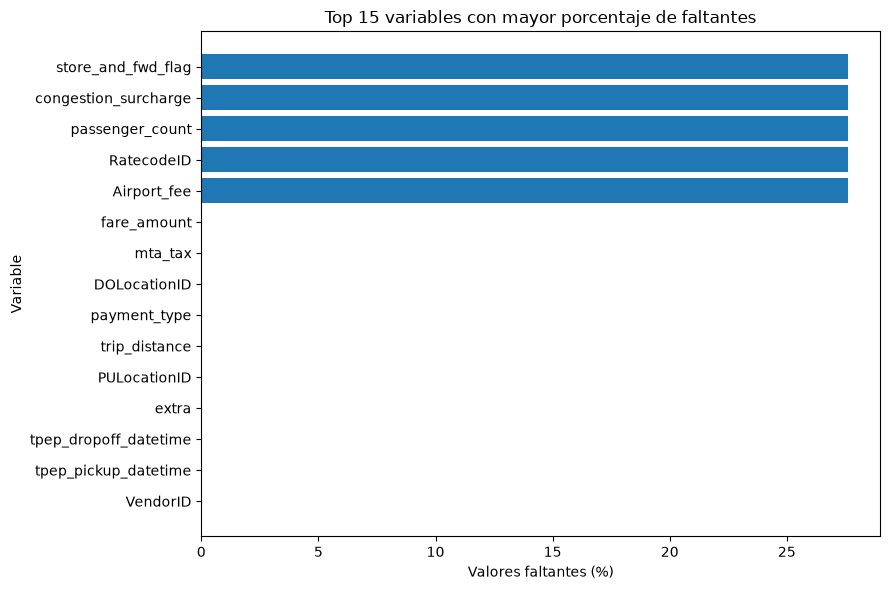

In [9]:
top_missing = missing_pct.head(15).sort_values("missing_pct")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_missing.index, top_missing["missing_pct"])
ax.set_title("Top 15 variables con mayor porcentaje de faltantes")
ax.set_xlabel("Valores faltantes (%)")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")


Confirma visualmente lo observado en la tabla de faltantes: cinco variables comparten el mismo 27.6% de faltantes (`passenger_count`, `congestion_surcharge`, `store_and_fwd_flag`, `RatecodeID`, `Airport_fee`), mientras que el resto de columnas —incluidas las marcas de tiempo usadas para construir el objetivo— no presentan faltantes. El patrón escalonado (todas al mismo nivel) refuerza que el origen es un subconjunto de registros sin reportar esos campos, no un faltante aleatorio disperso.


### Visualización 2 - Distribución de la variable objetivo

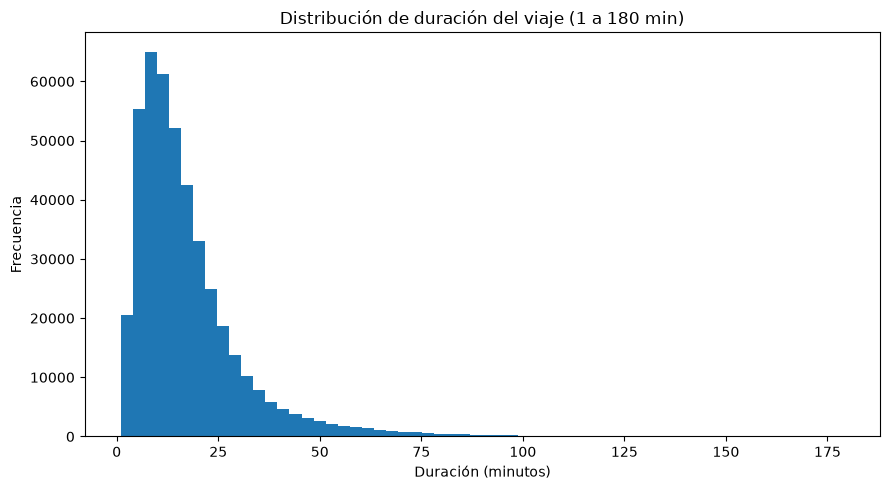

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(valid_sample["duration_min"], bins=60)
ax.set_title("Distribución de duración del viaje (1 a 180 min)")
ax.set_xlabel("Duración (minutos)")
ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "02_duration_distribution.png", dpi=150, bbox_inches="tight")


El histograma confirma la asimetría hacia la derecha vista en el `describe()`: la mayoría de los viajes se concentra entre 5 y 20 minutos, con una cola larga y decreciente hasta el límite de 180 minutos. No aparece una segunda moda ni discontinuidades sospechosas dentro del rango filtrado, lo que respalda usar este rango para el baseline.


### Visualización 3 - Número de viajes por hora de recogida

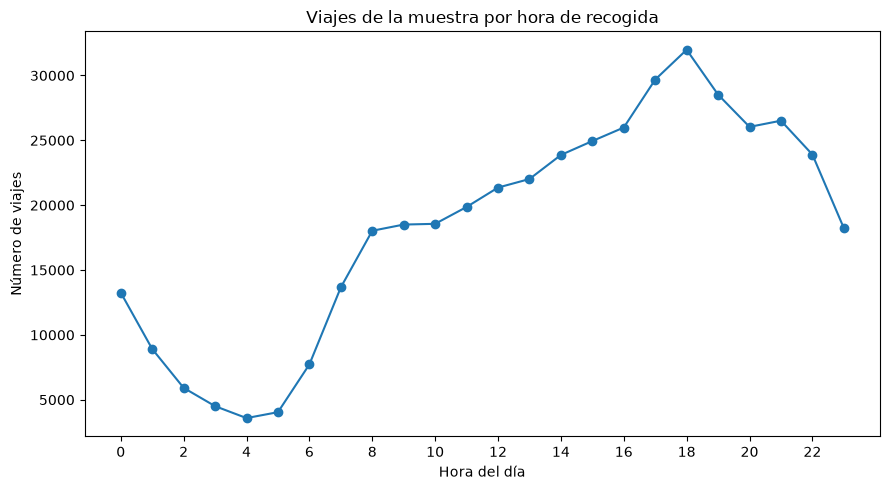

In [11]:
trips_by_hour = (
    valid_sample.groupby("pickup_hour", observed=True)
    .size()
    .reindex(range(24), fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(trips_by_hour.index, trips_by_hour.values, marker="o")
ax.set_title("Viajes de la muestra por hora de recogida")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Número de viajes")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "03_trips_by_hour.png", dpi=150, bbox_inches="tight")


La demanda tiene un patrón claramente no uniforme a lo largo del día: la hora pico es las **18:00** (~31,984 viajes en la muestra) y el mínimo ocurre a las **4:00** (~3,586 viajes), casi 9 veces menos. Esto confirma que la hora de recogida es una variable informativa para el modelo y que evaluar el modelo agregando todas las horas por igual podría ocultar un desempeño distinto entre horas pico y valle (se analizará en el análisis de errores por segmento en etapas posteriores).


### Visualización 4 - Mediana de duración por hora

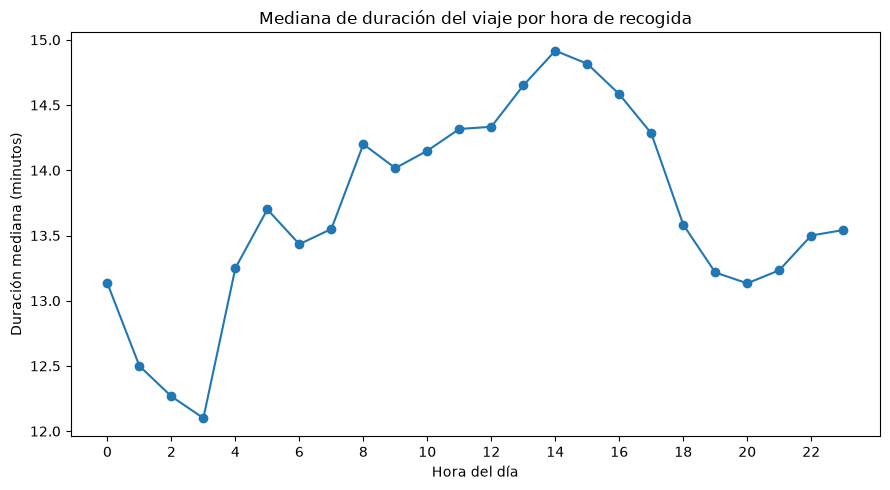

In [12]:
median_duration_by_hour = (
    valid_sample.groupby("pickup_hour", observed=True)["duration_min"]
    .median()
    .reindex(range(24))
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(median_duration_by_hour.index, median_duration_by_hour.values, marker="o")
ax.set_title("Mediana de duración del viaje por hora de recogida")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Duración mediana (minutos)")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "04_median_duration_by_hour.png", dpi=150, bbox_inches="tight")


La duración mediana varía relativamente poco entre horas (entre ~12.1 min a las 3:00 y ~14.9 min a las 14:00), a pesar de que el *volumen* de viajes cambia mucho más (visualización anterior). Esto sugiere que la hora del día aporta más información sobre *cuántos* viajes ocurren que sobre *cuánto duran* individualmente, aunque el efecto no es nulo y puede combinarse con otras variables (zona, día de la semana) para mejorar la predicción.


### Visualización 5 - Zonas de recogida más frecuentes

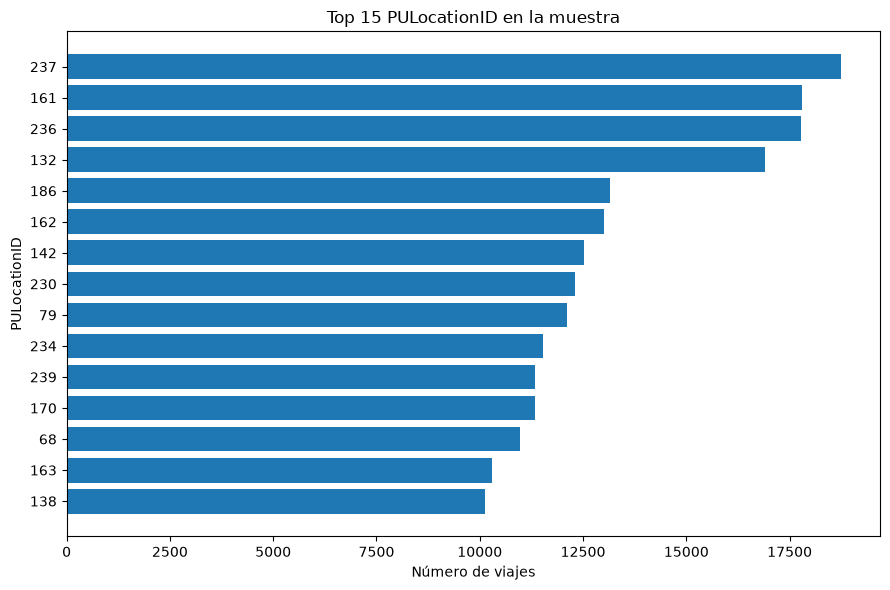

In [13]:
top_pu = (
    valid_sample["PULocationID"]
    .value_counts(dropna=False)
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_pu.index.astype(str), top_pu.values)
ax.set_title("Top 15 PULocationID en la muestra")
ax.set_xlabel("Número de viajes")
ax.set_ylabel("PULocationID")
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "05_top_pickup_zones.png", dpi=150, bbox_inches="tight")


La demanda está fuertemente concentrada geográficamente: las 5 zonas de recogida más frecuentes (`PULocationID` 237, 161, 236, 132, 186, todas en Manhattan/aeropuertos según el diccionario de zonas de TLC) explican por sí solas cerca del **19%** de los viajes de la muestra, sobre un total de más de 250 zonas posibles. Esto confirma un sesgo geográfico esperado: el modelo verá muchas más observaciones de estas zonas que de zonas periféricas, lo que deberá considerarse al evaluar el desempeño por segmento y al interpretar la importancia de `PULocationID`/`DOLocationID`.


### Visualización 6 - Distancia recorrida vs. duración

`trip_distance` se usa aquí únicamente como variable de diagnóstico exploratorio. No se incorporará al modelo principal porque corresponde a la distancia efectivamente recorrida y puede introducir leakage para una predicción realizada al inicio del viaje.


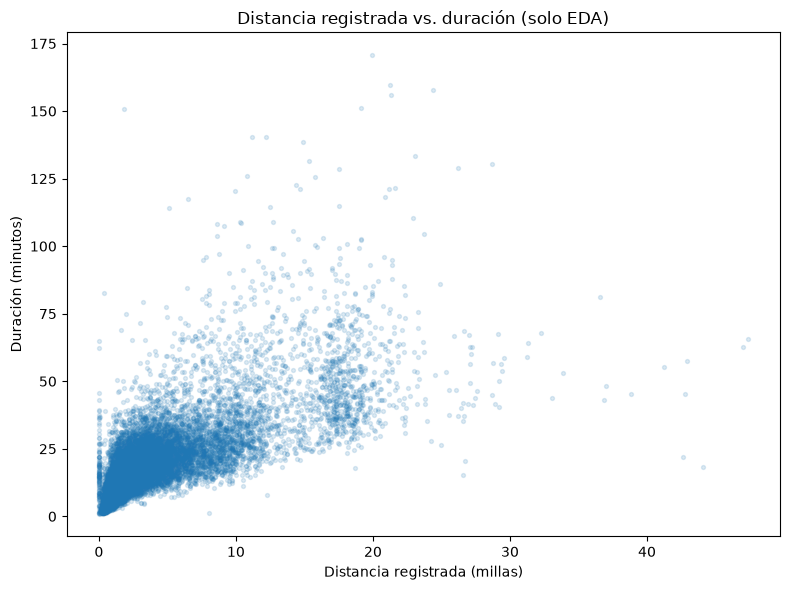

In [14]:
scatter_df = valid_sample.loc[
    valid_sample["trip_distance"].between(0, 50, inclusive="right"),
    ["trip_distance", "duration_min"]
].sample(
    n=min(20_000, len(valid_sample)),
    random_state=RANDOM_STATE
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scatter_df["trip_distance"], scatter_df["duration_min"], alpha=0.15, s=8)
ax.set_title("Distancia registrada vs. duración (solo EDA)")
ax.set_xlabel("Distancia registrada (millas)")
ax.set_ylabel("Duración (minutos)")
plt.tight_layout()
plt.show()

fig.savefig(FIG_DIR / "06_distance_vs_duration.png", dpi=150, bbox_inches="tight")


Existe una correlación positiva fuerte entre la distancia registrada y la duración (r ≈ 0.75 en la muestra filtrada a 0-50 millas), lo cual es razonable: viajes más largos tardan más. Sin embargo, la nube de puntos muestra dispersión considerable para una misma distancia (tráfico, hora, zona), lo que confirma que `trip_distance` sería un predictor fuerte pero **no puede usarse** porque solo se conoce al finalizar el viaje (leakage). Esta correlación sirve como referencia de cuánta señal se "pierde" al no poder usar la distancia real, y motiva construir features de proxy disponibles antes del viaje (por ejemplo, distancia euclidiana/Haversine entre las coordenadas del centroide de `PULocationID` y `DOLocationID`, si se decide incorporarla en etapas posteriores).


## 6. Outliers y registros sospechosos

Los siguientes conteos se calcularon sobre los archivos mensuales completos y sirven como diagnóstico inicial.

No se eliminarán registros silenciosamente. Toda regla de limpieza utilizada en el modelado deberá quedar documentada.


In [15]:
quality_df


,month,rows,duration_le_0,duration_gt_180,trip_distance_le_0,trip_distance_gt_100,fare_amount_lt_0,passenger_count_missing,passenger_count_gt_6
0,2026-01,3724889,45070,1755,125738,162,39463,1088058,7
1,2026-02,3399866,40598,1528,123250,172,26721,1023317,4
2,2026-03,3952451,49133,1181,121210,161,20724,945748,3


Los conteos sospechosos son consistentes entre los tres meses (sin un mes atípico), lo que sugiere errores sistemáticos del proceso de registro y no un incidente puntual. Cada mes tiene entre 40 mil y 49 mil viajes con duración ≤ 0 y alrededor de 120 mil con distancia registrada ≤ 0, además de decenas de miles de tarifas negativas por mes. `passenger_count` falta en aproximadamente un millón de viajes por mes, coherente con el 27.6% de faltantes observado antes.


In [16]:
quality_totals = quality_df.drop(columns="month").sum(numeric_only=True)
quality_totals.to_frame("total")


,total
rows,11077206
duration_le_0,134801
duration_gt_180,4464
trip_distance_le_0,370198
trip_distance_gt_100,495
fare_amount_lt_0,86908
passenger_count_missing,3057123
passenger_count_gt_6,14


Sobre el total de 11,077,206 viajes: **134,801 (1.22%)** tienen duración ≤ 0, **4,464 (0.04%)** superan las 180 min, **370,198 (3.34%)** tienen distancia registrada ≤ 0, y **86,908 (0.78%)** tienen tarifa negativa. `passenger_count` falta en **3,057,123 viajes (27.6%)**, consistente con el análisis de faltantes. En conjunto, los registros claramente problemáticos de duración (≤0 o >180 min) representan solo ~1.26% del total, lo que confirma que excluirlos para el baseline no distorsiona significativamente la muestra, aunque para un modelo final convendrá revisar si la distancia ≤ 0 o la tarifa negativa deben tratarse por separado en lugar de descartarse junto con la duración.


### Interpretación inicial de calidad

Se consideran señales de revisión:

- duraciones menores o iguales a cero;
- duraciones extremadamente altas;
- distancia menor o igual a cero;
- distancias extraordinariamente altas;
- tarifas negativas;
- pasajeros faltantes o valores fuera de un rango usual.

Que un registro sea marcado como sospechoso **no implica automáticamente que deba eliminarse**. Las reglas definitivas se justificarán según su efecto sobre el objetivo y el modelo.


## 7. Discusión inicial de leakage, sesgos y limitaciones

### Leakage

No deben utilizarse para predecir la duración al inicio del viaje variables que solo se conocen al terminarlo. Entre las principales:

- `tpep_dropoff_datetime`: define el objetivo.
- `trip_distance`: distancia efectivamente recorrida.
- `fare_amount`, `tip_amount`, `tolls_amount`, `total_amount`: resultados monetarios posteriores.
- `payment_type`: se conoce al cierre del viaje.
- `RatecodeID`: el diccionario la describe como la tarifa final vigente al terminar el viaje.

El uso de estas variables podría mejorar artificialmente la métrica sin representar un escenario real de predicción.

### DOLocationID

Se utilizará solo bajo una definición explícita: la predicción ocurre al comienzo del viaje **después de que el pasajero ha comunicado su destino**. En una aplicación donde el destino no se conoce, `DOLocationID` tendría que excluirse.

### Sesgos potenciales

1. La distribución de viajes puede estar concentrada en determinadas zonas y horarios.
2. El desempeño puede ser distinto entre zonas frecuentes y poco frecuentes.
3. Tres meses de invierno no representan necesariamente todo el año.
4. Los taxis amarillos no representan toda la movilidad de Nueva York ni necesariamente otros servicios de transporte.
5. Los viajes que no quedan registrados correctamente pueden introducir sesgo de calidad.

### Limitaciones

1. No se dispone de la ruta exacta prevista al inicio del viaje.
2. No se incluyen directamente tráfico, clima, obras o eventos.
3. La zona de destino es más gruesa que una dirección exacta.
4. NYC TLC indica que los registros son aportados por proveedores tecnológicos y no garantiza completamente su exactitud.
5. Los resultados de enero-marzo no deben generalizarse automáticamente a otros períodos sin validación temporal.


### Resultados que respaldan esta discusión

- **Leakage:** la correlación distance–duration (r≈0.75, Visualización 6) confirma que `trip_distance` sería un predictor muy fuerte si se permitiera usarla, lo que hace más grave excluirla incorrectamente: un modelo que la incluyera por error mostraría una mejora artificial e injustificada frente al baseline.
- **Sesgo geográfico:** las 5 zonas de recogida más frecuentes concentran ~19% de los viajes (Visualización 5), sobre más de 250 zonas posibles. El modelo aprenderá mejor sobre zonas centrales que sobre zonas periféricas con pocos viajes.
- **Sesgo temporal:** el volumen de viajes varía casi 9× entre la hora pico (18:00) y la hora de menor demanda (4:00), mientras que la duración mediana varía mucho menos (Visualizaciones 3 y 4). Un modelo evaluado solo con una métrica agregada podría enmascarar un peor desempeño en horas de baja demanda, donde hay menos datos de entrenamiento.
- **Calidad de origen:** 1.22% de los viajes tiene duración ≤0 o >180 min, 3.34% tiene distancia registrada ≤0 y 0.78% tiene tarifa negativa (sección 6). Estos registros no se eliminan silenciosamente del dataset completo; solo se excluyen de forma documentada al construir el baseline y las visualizaciones filtradas.
- **Faltantes estructurados:** el 27.6% de faltantes compartido por `passenger_count`, `RatecodeID`, `congestion_surcharge`, `store_and_fwd_flag` y `Airport_fee` (sección 3) sugiere que provienen de un subconjunto específico de proveedores/registros, no de faltantes aleatorios — su tratamiento (imputación vs. exclusión vs. indicador de faltante) deberá decidirse con esa estructura en mente, no como un caso genérico de MCAR.
- **Representatividad:** el dataset solo cubre viajes de taxi amarillo con licencia TLC; no representa viajes en Uber/Lyft, otros boroughs con menor cobertura, ni la movilidad general de la ciudad.

Estas observaciones son iniciales; en la entrega final se profundizará con análisis de errores por segmento (hora, zona, día de la semana) una vez entrenados modelos más allá del baseline.


## 8. Baseline simple y honesto

Se utilizará un **DummyRegressor con estrategia de mediana**.

### Partición temporal

- Entrenamiento: enero + febrero de 2026.
- Validación: marzo de 2026.

No se mezclan aleatoriamente viajes del futuro con el entrenamiento.

### Regla de calidad para el primer baseline

Se conservan duraciones entre 1 y 180 minutos.

La regla se aplica de la misma manera en entrenamiento y validación.


In [17]:
baseline_cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
]

train_parts = []
for month in ("2026-01", "2026-02"):
    temp = load_month(paths[month], columns=baseline_cols)
    temp = add_duration(temp)
    temp = temp.loc[valid_duration_mask(temp, 1, 180), ["duration_min"]]
    train_parts.append(temp)

train_baseline = pd.concat(train_parts, ignore_index=True)

val_baseline = load_month(paths["2026-03"], columns=baseline_cols)
val_baseline = add_duration(val_baseline)
val_baseline = val_baseline.loc[
    valid_duration_mask(val_baseline, 1, 180),
    ["duration_min"]
]

print("Entrenamiento:", f"{len(train_baseline):,}", "viajes")
print("Validación:", f"{len(val_baseline):,}", "viajes")


Entrenamiento: 6,964,120 viajes
Validación: 3,862,080 viajes


El conjunto de entrenamiento (enero-febrero, tras aplicar el filtro de 1-180 min) queda con **6,964,120 viajes** y el de validación (marzo) con **3,862,080 viajes**. La proporción de filas retenidas es similar a la observada en la muestra exploratoria (~97-98%), lo que confirma que la regla de calidad se comporta de forma estable al aplicarse sobre los archivos completos y no solo sobre la muestra.


In [18]:
X_train_dummy = np.zeros((len(train_baseline), 1), dtype=np.int8)
X_val_dummy = np.zeros((len(val_baseline), 1), dtype=np.int8)

y_train = train_baseline["duration_min"].to_numpy()
y_val = val_baseline["duration_min"].to_numpy()

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train_dummy, y_train)
y_pred = baseline.predict(X_val_dummy)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)
train_median = float(np.median(y_train))

baseline_metrics = {
    "train_months": ["2026-01", "2026-02"],
    "validation_month": "2026-03",
    "duration_filter_min": 1,
    "duration_filter_max": 180,
    "train_rows": int(len(y_train)),
    "validation_rows": int(len(y_val)),
    "train_median_minutes": train_median,
    "MAE_minutes": float(mae),
    "RMSE_minutes": float(rmse),
    "R2": float(r2),
}

pd.DataFrame([baseline_metrics])


,train_months,validation_month,duration_filter_min,duration_filter_max,train_rows,validation_rows,train_median_minutes,MAE_minutes,RMSE_minutes,R2
0,"[2026-01, 2026-02]",2026-03,1,180,6964120,3862080,13.950,9.175,14.789,-0.058


In [19]:
print(f"Mediana de entrenamiento : {train_median:.3f} min")
print(f"MAE de validación        : {mae:.3f} min")
print(f"RMSE de validación       : {rmse:.3f} min")
print(f"R² de validación         : {r2:.4f}")

with open(OUTPUT_DIR / "baseline_metrics.json", "w", encoding="utf-8") as f:
    json.dump(baseline_metrics, f, indent=2, ensure_ascii=False)

summary = {
    "months": list(MONTHS),
    "total_rows": int(metadata_df["rows"].sum()),
    "columns": int(metadata_df.loc[0, "columns"]),
    "visualization_sample_rows": int(len(df_sample)),
    "baseline": baseline_metrics,
}

with open(OUTPUT_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("\nArchivos guardados:")
print("-", OUTPUT_DIR / "baseline_metrics.json")
print("-", OUTPUT_DIR / "eda_summary.json")


Mediana de entrenamiento : 13.950 min
MAE de validación        : 9.175 min
RMSE de validación       : 14.789 min
R² de validación         : -0.0577

Archivos guardados:
- /home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi/outputs/baseline_metrics.json
- /home/jairocatacora/Escritorio/ML/proyecto-final-nyc-taxi/outputs/eda_summary.json


## 9. Lectura del baseline

El baseline no pretende ser un buen modelo. Su función es establecer un punto de comparación honesto.

Al presentar los resultados:

- **MAE:** interpretar como error absoluto promedio en minutos.
- **RMSE:** comparar con MAE; si es bastante mayor, puede indicar presencia de errores grandes.
- **R²:** en un DummyRegressor constante puede ser cercano a cero o negativo; no debe interpretarse de manera aislada.

El siguiente modelo deberá compararse contra estos mismos datos de validación y las mismas reglas de calidad.


## 10. Conclusiones

1. El problema se formula como una regresión sobre la duración de un viaje individual.
2. La validación es temporal (enero-febrero para entrenar, marzo para validar) para evitar mezclar información futura en el entrenamiento.
3. Se identificaron variables con alto riesgo de leakage (`trip_distance`, montos monetarios, `payment_type`, `RatecodeID`) que no se usarán en el modelo principal; la correlación distancia-duración (r≈0.75) confirma cuánta señal habría que "descartar" honestamente.
4. El dataset requiere controles de calidad documentados: ~1.22% de los viajes tiene duración ≤0 o >180 min, 3.34% distancia ≤0, 0.78% tarifa negativa, y 27.6% de faltantes concentrados en 5 columnas relacionadas.
5. Se identificaron sesgos relevantes: geográfico (5 zonas concentran ~19% de los viajes) y temporal (el volumen de viajes varía ~9× entre horas, aunque la duración mediana varía poco).
6. El baseline de mediana proporciona el punto mínimo de referencia cuantitativo (MAE 9.175 min, RMSE 14.789 min, R² -0.058).
7. La siguiente etapa será construir variables disponibles al inicio del viaje y comparar regresión lineal, modelos basados en árboles y gradient boosting frente a este baseline.
